In [1]:
import os
import sys
from collections import defaultdict
from typing import Dict, Iterable, List, Mapping, MutableMapping, Optional, Tuple

import numpy as np
import matplotlib.pyplot as plt
import stim
import sinter
from stimbposd import SinterDecoder_BPOSD, sinter_decoders
import pymatching

root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if root not in sys.path:
    sys.path.append(root)

from scripts.circuit_pauli_override import *

print('stim', stim.__version__)
print('sinter', getattr(sinter, '__version__', ''))

stim 1.15.0
sinter 1.15.0


In [2]:
def unrotated_memory_qubits(
    distance: int,
    rounds: int,
    *,
    task: str = "surface_code:unrotated_memory_z",
) -> List[int]:
    """Return sorted qubit indices used by the generated surface-code circuit."""

    marker = stim.Circuit.generated(
        task,
        rounds=rounds,
        distance=distance,
        after_clifford_depolarization=0.0,
        after_reset_flip_probability=0.0,
        before_measure_flip_probability=0.0,
        before_round_data_depolarization=0.0,
    )
    qubits = set()
    for op in marker:
        if op.name == "QUBIT_COORDS":
            for target in op.targets_copy():
                qubits.add(int(target.value))
    return sorted(qubits)

In [3]:
distance_3_t12 = [
    (0, 43.6, 12.2),
    (1, 100.7, 159.0),
    (2, 103.3, 182.8),
    (3, 110.9, 228.6),
    (4, 123.1, 114.0),
    (5, 111.0, 215.8),
    (6, 107.6, 133.7),
    (7, 101.8, 158.8),
    (8, 16.5, 100.0),
    (9, 77.6, 11.6),
    (10, 61.1, 8.6),
    (11, 71.1, 11.2),
    (12, 66.9, 11.9),
]

distance_5_t12 = [
    (0, 65.5, 33.0),
    (1, 34.7, 69.4),
    (2, 89.8, 111.6),
    (3, 96.7, 90.7),
    (4, 91.1, 130.0),
    (5, 94.9, 91.7),
    (6, 92.0, 187.7),
    (7, 95.3, 155.8),
    (8, 98.3, 110.1),
    (9, 100.7, 159.0),
    (10, 103.3, 182.8),
    (11, 110.9, 228.6),
    (12, 123.1, 114.0),
    (13, 111.0, 215.8),
    (14, 107.6, 133.7),
    (15, 101.8, 158.8),
    (16, 98.4, 161.7),
    (17, 97.2, 151.2),
    (18, 93.0, 116.5),
    (19, 91.7, 131.4),
    (20, 91.6, 179.1),
    (21, 90.7, 151.2),
    (22, 90.5, 122.4),
    (23, 89.7, 37.2),
    (24, 33.6, 101.9),
    (25, 72.3, 25.6),
    (26, 52.7, 21.6),
    (27, 86.9, 20.2),
    (28, 83.5, 17.9),
    (29, 68.9, 17.0),
    (30, 43.6, 12.2),
    (31, 77.6, 11.6),
    (32, 61.1, 8.6),
    (33, 71.1, 11.2),
    (34, 66.9, 11.9),
    (35, 16.5, 100.0),
    (36, 72.8, 17.6),
    (37, 83.5, 19.2),
    (38, 78.0, 21.0),
    (39, 57.8, 25.1),
    (40, 29.9, 47.0),
]

distance_7_t12 = [
    (0, 50.8, 86.1),
    (1, 53.3, 64.1),
    (2, 54.4, 117.4),
    (3, 78.5, 159.1),
    (4, 79.0, 80.8),
    (5, 81.3, 140.5),
    (6, 82.6, 117.8),
    (7, 83.1, 98.4),
    (8, 83.8, 199.4),
    (9, 84.4, 161.0),
    (10, 84.8, 84.5),
    (11, 86.8, 120.0),
    (12, 88.5, 144.8),
    (13, 89.3, 147.7),
    (14, 89.8, 111.6),
    (15, 96.7, 90.7),
    (16, 91.1, 130.0),
    (17, 94.9, 91.7),
    (18, 92.0, 187.7),
    (19, 95.3, 155.8),
    (20, 98.3, 110.1),
    (21, 100.7, 159.0),
    (22, 103.3, 182.8),
    (23, 110.9, 228.6),
    (24, 123.1, 114.0),
    (25, 111.0, 215.8),
    (26, 107.6, 133.7),
    (27, 101.8, 158.8),
    (28, 98.4, 161.7),
    (29, 97.2, 151.2),
    (30, 93.0, 116.5),
    (31, 91.7, 131.4),
    (32, 91.6, 179.1),
    (33, 90.7, 151.2),
    (34, 90.5, 122.4),
    (35, 89.6, 154.0),
    (36, 88.7, 155.3),
    (37, 88.4, 131.1),
    (38, 85.8, 140.0),
    (39, 84.4, 115.5),
    (40, 84.1, 168.6),
    (41, 118.4, 83.2),
    (42, 82.9, 172.6),
    (43, 82.0, 140.0),
    (44, 81.3, 104.0),
    (45, 78.9, 95.2),
    (46, 55.6, 119.9),
    (47, 53.7, 113.4),
    (48, 52.9, 127.3),
    (49, 71.7, 48.4),
    (50, 54.5, 46.1),
    (51, 70.4, 44.7),
    (52, 74.4, 44.5),
    (53, 54.1, 42.0),
    (54, 41.1, 150.5),
    (55, 71.8, 38.8),
    (56, 38.1, 95.0),
    (57, 34.7, 39.4),
    (58, 65.5, 33.0),
    (59, 72.3, 25.6),
    (60, 52.7, 21.6),
    (61, 86.9, 20.2),
    (62, 83.5, 17.9),
    (63, 68.9, 17.0),
    (64, 43.6, 12.2),
    (65, 77.6, 11.6),
    (66, 61.1, 8.6),
    (67, 71.1, 11.2),
    (68, 66.9, 11.9),
    (69, 16.5, 100.0),
    (70, 72.8, 17.6),
    (71, 83.5, 19.2),
    (72, 78.0, 21.0),
    (73, 57.8, 25.1),
    (74, 29.9, 47.0),
    (75, 33.6, 101.9),
    (76, 89.7, 37.2),
    (77, 38.1, 53.0),
    (78, 39.6, 80.0),
    (79, 73.3, 41.9),
    (80, 44.3, 80.4),
    (81, 44.7, 81.7),
    (82, 111.7, 44.8),
    (83, 74.0, 47.4),
    (84, 70.1, 50.7),
]


distance_3_t12 = fix_physical_t1_t1(distance_3_t12)
distance_5_t12 = fix_physical_t1_t1(distance_5_t12)
distance_7_t12 = fix_physical_t1_t1(distance_7_t12)

In [4]:
rng = np.random.default_rng(seed=23)

distances = [3, 5, 7]
rounds_per_distance = {d: d * 3 for d in distances}

qubits_by_distance = {
    d: unrotated_memory_qubits(distance=d, rounds=rounds_per_distance[d])
    for d in distances
}

# Use distance_7_t12 for all distances
base_tables = {
    3: np.array(distance_7_t12, dtype=object),
    5: np.array(distance_7_t12, dtype=object),
    7: np.array(distance_7_t12, dtype=object),
}



def sample_qubit_layout(distance: int, rng) -> dict[int, tuple[float, float]]:
    qubits = qubits_by_distance[distance]
    table = base_tables[distance]
    repeats = (len(qubits) + len(table) - 1) // len(table)
    expanded = np.tile(table, (repeats, 1))[: len(qubits)]
    selected = expanded[rng.permutation(len(expanded))]
    return {int(q): (float(entry[1]), float(entry[2])) for q, entry in zip(qubits, selected)}

_preview_layout = sample_qubit_layout(distances[-1], rng)
_preview_layout.items()


dict_items([(0, (98.4, 161.7)), (1, (78.0, 21.0)), (2, (111.7, 44.8)), (3, (73.3, 41.9)), (4, (41.1, 82.2)), (5, (91.1, 130.0)), (6, (81.3, 104.0)), (7, (71.1, 11.2)), (8, (94.9, 91.7)), (9, (123.1, 114.0)), (10, (54.4, 108.8)), (11, (88.4, 131.1)), (12, (44.3, 80.4)), (13, (79.0, 80.8)), (14, (53.3, 64.1)), (15, (39.6, 79.2)), (16, (91.7, 131.4)), (17, (72.8, 17.6)), (18, (100.7, 159.0)), (19, (43.6, 12.2)), (20, (92.0, 184.0)), (21, (82.9, 165.8)), (22, (96.7, 90.7)), (23, (74.0, 47.4)), (24, (86.9, 20.2)), (25, (29.9, 47.0)), (26, (52.7, 21.6)), (27, (85.8, 140.0)), (28, (50.8, 86.1)), (29, (111.7, 44.8)), (30, (84.4, 161.0)), (31, (100.7, 159.0)), (32, (83.1, 98.4)), (33, (78.5, 157.0)), (34, (34.7, 39.4)), (35, (110.9, 221.8)), (36, (103.3, 182.8)), (37, (34.7, 39.4)), (38, (29.9, 47.0)), (39, (89.6, 154.0)), (40, (110.9, 221.8)), (41, (84.8, 84.5)), (42, (71.7, 48.4)), (43, (81.3, 104.0)), (44, (82.0, 140.0)), (45, (81.3, 140.5)), (46, (78.9, 95.2)), (47, (83.1, 98.4)), (48, (72.

In [5]:
# Define multiple T1/T2 configurations for i.i.d. simulations
iid_configurations = {
    'baseline': (67.4, 48.7),
    'low': (62.1, 42.8),
    'high': (89.1, 138.1),
}

# Create uniform mappings for each configuration
uniform_t1t2_dict_configs = {}
for config_name, (t1, t2) in iid_configurations.items():
    uniform_t1t2_dict_configs[config_name] = {}
    for distance in [3, 5, 7]:
        qubits = qubits_by_distance[distance]
        uniform_t1t2_dict_configs[config_name][distance] = {q: (t1, t2) for q in qubits}

print("Created i.i.d. configurations:")
for config_name, (t1, t2) in iid_configurations.items():
    print(f"  {config_name}: T1={t1} µs, T2={t2} µs")


Created i.i.d. configurations:
  baseline: T1=67.4 µs, T2=48.7 µs
  low: T1=62.1 µs, T2=42.8 µs
  high: T1=89.1 µs, T2=138.1 µs


In [6]:
def pseudo_threshold(records_for_one_distance):
    # records: list of (physical_p, logical_per_round), sorted by physical_p
    p_vals = np.array([r['physical'] for r in records_for_one_distance])
    l_vals = np.array([r['logical'] for r in records_for_one_distance])
    diff = l_vals - p_vals

    # exact hit?
    zeros = np.where(np.isclose(diff, 0))[0]
    if len(zeros):
        return p_vals[zeros[0]]

    # find sign change
    signs = np.sign(diff)
    flips = np.where(signs[:-1] * signs[1:] < 0)[0]
    if not len(flips):
        return None  # no intersection inside sampled range

    i = flips[0]
    p1, p2 = p_vals[i], p_vals[i+1]
    d1, d2 = diff[i], diff[i+1]
    # linear interpolation of root between (p1,d1) and (p2,d2)
    return p1 - d1 * (p2 - p1) / (d2 - d1)

def threshold_per_dictance(collected_surface_code_stats):
    records_by_distance = {}
    for stat in collected_surface_code_stats:
        p = stat.json_metadata['p']
        per_shot = stat.errors / stat.shots
        logical = sinter.shot_error_rate_to_piece_error_rate(
        shot_error_rate=per_shot,
        pieces=stat.json_metadata['r'],
    )
    
        records_by_distance.setdefault(stat.json_metadata['d'], []).append({
            'physical': p,
            'logical': logical,
        })
    
    # sort and compute
    thresholds = {}
    for d, recs in records_by_distance.items():
        recs.sort(key=lambda r: r['physical'])
        thresholds[d] = pseudo_threshold(recs)

    return thresholds

def threshold_per_distance_with_permutations(collected_surface_code_stats):
    """
    Compute thresholds with statistics across permutations.
    Returns dict with structure: {distance: {'mean': float, 'std': float, 'values': list}}
    """
    # Group by distance and permutation
    records_by_distance_perm = {}
    for stat in collected_surface_code_stats:
        d = stat.json_metadata['d']
        p = stat.json_metadata['p']
        perm = stat.json_metadata.get('perm', 0)  # Default to 0 if no perm key
        
        per_shot = stat.errors / stat.shots
        logical = sinter.shot_error_rate_to_piece_error_rate(
            shot_error_rate=per_shot,
            pieces=stat.json_metadata['r'],
        )
        
        key = (d, perm)
        records_by_distance_perm.setdefault(key, []).append({
            'physical': p,
            'logical': logical,
        })
    
    # Compute threshold for each (distance, permutation) pair
    thresholds_by_distance = {}
    for (d, perm), recs in records_by_distance_perm.items():
        recs.sort(key=lambda r: r['physical'])
        threshold = pseudo_threshold(recs)
        if threshold is not None:
            thresholds_by_distance.setdefault(d, []).append(threshold)
    
    # Compute statistics across permutations
    result = {}
    for d, threshold_values in thresholds_by_distance.items():
        result[d] = {
            'mean': np.mean(threshold_values),
            'std': np.std(threshold_values),
            'values': threshold_values,
            'count': len(threshold_values)
        }
    
    return result

## 3D Surface Plot: T1 vs T2 vs Pseudo-threshold (Distance 5)

Create a 3D surface plot showing how pseudo-threshold varies with both T1 and T2 simultaneously, with the constraint T2 ≤ 2*T1.

In [7]:
# Define T1 and T2 grid for 3D surface plot (distance 5 only)
# Constraint: T2 <= 2*T1

t1_grid = np.linspace(40, 100, 10)  # 10 points from 40 to 100 µs
t2_grid = np.linspace(20, 120, 12)  # 12 points from 20 to 120 µs

# Create configurations that satisfy T2 <= 2*T1
configs_3d = []
for t1 in t1_grid:
    for t2 in t2_grid:
        if t2 <= 2 * t1:  # Apply constraint
            configs_3d.append((t1, t2))

print(f"Total configurations to simulate: {len(configs_3d)}")
print(f"T1 range: [{min(t1_grid):.1f}, {max(t1_grid):.1f}] µs")
print(f"T2 range: [{min(t2_grid):.1f}, {max(t2_grid):.1f}] µs")
print(f"Constraint: T2 ≤ 2*T1")
print(f"\nTotal simulations: {len(configs_3d)} configurations × 10 noise levels = {len(configs_3d) * 10} tasks")
print(f"(Simulating distance 5 only)")


Total configurations to simulate: 110
T1 range: [40.0, 100.0] µs
T2 range: [20.0, 120.0] µs
Constraint: T2 ≤ 2*T1

Total simulations: 110 configurations × 10 noise levels = 1100 tasks
(Simulating distance 5 only)


In [8]:
# Run simulations for all T1-T2 combinations (distance 5 only)
# Create checkpoints directory if it doesn't exist
os.makedirs('checkpoints', exist_ok=True)

collected_stats_3d = {}

distance = 5
noise_levels = [0.001, 0.003, 0.006, 0.01, 0.015, 0.02, 0.0225, 0.025, 0.03, 0.035]

for idx, (t1, t2) in enumerate(configs_3d):
    config_key = f"T1={t1:.1f}_T2={t2:.1f}"
    print(f"\n{'='*70}")
    print(f"Progress: {idx+1}/{len(configs_3d)} - T1={t1:.1f} µs, T2={t2:.1f} µs")
    print(f"{'='*70}")
    
    # Create uniform mapping for this configuration
    qubits = qubits_by_distance[distance]
    uniform_mapping = {q: (t1, t2) for q in qubits}
    
    # Create tasks for distance 5
    tasks = [
        sinter.Task(
            circuit = create_scaled_circuit_from_t1_t2(
                rounds=distance*3,
                distance=distance,
                t1t2_mapping=uniform_mapping,
                idle_duration_us=0.35,
                target_error_rate=noise,
            ),
            json_metadata={'d': distance, 'r': distance*3, 'p': noise, 't1': t1, 't2': t2},
        )
        for noise in noise_levels
    ]
    
    # Collect statistics
    collected_stats_3d[config_key] = sinter.collect(
        num_workers=144,
        tasks=tasks,
        decoders=['pymatching'],
        max_shots=1_000_000,
        max_errors=50_000,
        print_progress=False,
        save_resume_filepath=f"checkpoints/3d_grid_{config_key}.checkpoint"
    )

print(f"\n{'='*70}")
print(f"Completed all 3D grid simulations!")
print(f"{'='*70}")


Progress: 1/110 - T1=40.0 µs, T2=20.0 µs

Progress: 2/110 - T1=40.0 µs, T2=29.1 µs

Progress: 2/110 - T1=40.0 µs, T2=29.1 µs

Progress: 3/110 - T1=40.0 µs, T2=38.2 µs

Progress: 3/110 - T1=40.0 µs, T2=38.2 µs

Progress: 4/110 - T1=40.0 µs, T2=47.3 µs

Progress: 4/110 - T1=40.0 µs, T2=47.3 µs

Progress: 5/110 - T1=40.0 µs, T2=56.4 µs

Progress: 5/110 - T1=40.0 µs, T2=56.4 µs

Progress: 6/110 - T1=40.0 µs, T2=65.5 µs

Progress: 6/110 - T1=40.0 µs, T2=65.5 µs

Progress: 7/110 - T1=40.0 µs, T2=74.5 µs

Progress: 7/110 - T1=40.0 µs, T2=74.5 µs

Progress: 8/110 - T1=46.7 µs, T2=20.0 µs

Progress: 8/110 - T1=46.7 µs, T2=20.0 µs

Progress: 9/110 - T1=46.7 µs, T2=29.1 µs

Progress: 9/110 - T1=46.7 µs, T2=29.1 µs

Progress: 10/110 - T1=46.7 µs, T2=38.2 µs

Progress: 10/110 - T1=46.7 µs, T2=38.2 µs

Progress: 11/110 - T1=46.7 µs, T2=47.3 µs

Progress: 11/110 - T1=46.7 µs, T2=47.3 µs

Progress: 12/110 - T1=46.7 µs, T2=56.4 µs

Progress: 12/110 - T1=46.7 µs, T2=56.4 µs

Progress: 13/110 - T1=46.7 

In [9]:
# Compute thresholds for all 3D configurations
thresholds_3d = {}

for config_key, stats in collected_stats_3d.items():
    # Extract T1 and T2 from config key
    parts = config_key.split('_')
    t1 = float(parts[0].split('=')[1])
    t2 = float(parts[1].split('=')[1])
    
    # Compute threshold for distance 5
    threshold = threshold_per_dictance(stats)[5]
    thresholds_3d[(t1, t2)] = threshold

print("Computed thresholds for all T1-T2 combinations")
print(f"Total data points: {len(thresholds_3d)}")
print(f"\nSample thresholds:")
print("=" * 60)
print(f"{'T1 (µs)':<10} {'T2 (µs)':<10} {'Threshold':<15}")
print("-" * 60)
for (t1, t2), threshold in list(thresholds_3d.items())[:5]:
    print(f"{t1:<10.1f} {t2:<10.1f} {threshold:<15.6f}")
print("..." if len(thresholds_3d) > 5 else "")
print("=" * 60)

Computed thresholds for all T1-T2 combinations
Total data points: 110

Sample thresholds:
T1 (µs)    T2 (µs)    Threshold      
------------------------------------------------------------
40.0       20.0       0.007573       
40.0       29.1       0.004740       
40.0       38.2       0.003482       
40.0       47.3       0.003102       
40.0       56.4       0.002277       
...


In [10]:
# Create INTERACTIVE 3D surface plot using Plotly
import plotly.graph_objects as go
from scipy.interpolate import griddata

# Prepare data for plotting
t1_data = np.array([t1 for (t1, t2) in thresholds_3d.keys()])
t2_data = np.array([t2 for (t1, t2) in thresholds_3d.keys()])
threshold_data = np.array([threshold for threshold in thresholds_3d.values()])

# Create a fine grid for interpolation
t1_fine = np.linspace(t1_data.min(), t1_data.max(), 100)
t2_fine = np.linspace(t2_data.min(), t2_data.max(), 100)
T1_mesh, T2_mesh = np.meshgrid(t1_fine, t2_fine)

# Interpolate threshold values on the fine grid
Threshold_mesh = griddata(
    (t1_data, t2_data), 
    threshold_data, 
    (T1_mesh, T2_mesh), 
    method='cubic'
)

# Apply constraint T2 <= 2*T1 to mask invalid regions
mask = T2_mesh > 2 * T1_mesh
Threshold_mesh[mask] = np.nan

# Create interactive 3D surface plot
fig = go.Figure()

# Add surface
fig.add_trace(go.Surface(
    x=T1_mesh,
    y=T2_mesh,
    z=Threshold_mesh,
    colorscale='Viridis',
    opacity=0.9,
    name='Interpolated Surface',
    colorbar=dict(
        title=dict(
            text='Pseudo-threshold',
            side='right',
            font=dict(size=14)
        ),
        len=0.7
    ),
    hovertemplate='T1: %{x:.1f} µs<br>T2: %{y:.1f} µs<br>Threshold: %{z:.6f}<extra></extra>'
))

# Add original data points as scatter
fig.add_trace(go.Scatter3d(
    x=t1_data,
    y=t2_data,
    z=threshold_data,
    mode='markers',
    marker=dict(
        size=4,
        color='red',
        opacity=0.8,
        symbol='circle',
        line=dict(color='darkred', width=1)
    ),
    name='Simulated Points',
    hovertemplate='T1: %{x:.1f} µs<br>T2: %{y:.1f} µs<br>Threshold: %{z:.6f}<extra></extra>'
))

# Update layout for better interactivity
fig.update_layout(
    title=dict(
        text='3D Interactive Surface: T1 vs T2 vs Pseudo-threshold (Distance 5, T2 ≤ 2*T1)',
        font=dict(size=16, family='Arial, sans-serif', color='black'),
        x=0.5,
        xanchor='center'
    ),
    scene=dict(
        xaxis=dict(
            title=dict(text='T1 (µs)', font=dict(size=14)),
            backgroundcolor='rgb(230, 230,230)',
            gridcolor='white',
            showbackground=True
        ),
        yaxis=dict(
            title=dict(text='T2 (µs)', font=dict(size=14)),
            backgroundcolor='rgb(230, 230,230)',
            gridcolor='white',
            showbackground=True
        ),
        zaxis=dict(
            title=dict(text='Pseudo-threshold', font=dict(size=14)),
            backgroundcolor='rgb(230, 230,230)',
            gridcolor='white',
            showbackground=True
        ),
        camera=dict(
            eye=dict(x=1.5, y=1.5, z=1.3)
        )
    ),
    width=1000,
    height=800,
    showlegend=True,
    legend=dict(
        x=0.7,
        y=0.9,
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='black',
        borderwidth=1
    ),
    hovermode='closest'
)

fig.show()

# Print statistics
print("\n3D Interactive Surface Plot Statistics:")
print("=" * 60)
print(f"T1 range: [{t1_data.min():.1f}, {t1_data.max():.1f}] µs")
print(f"T2 range: [{t2_data.min():.1f}, {t2_data.max():.1f}] µs")
print(f"Threshold range: [{threshold_data.min():.6f}, {threshold_data.max():.6f}]")
print(f"Number of simulated points: {len(threshold_data)}")
print(f"Constraint applied: T2 ≤ 2*T1")
print("=" * 60)
print("\n🖱️  TIP: Use your mouse to rotate, zoom, and pan the 3D plot!")


3D Interactive Surface Plot Statistics:
T1 range: [40.0, 100.0] µs
T2 range: [20.0, 120.0] µs
Threshold range: [0.001395, 0.028171]
Number of simulated points: 110
Constraint applied: T2 ≤ 2*T1

🖱️  TIP: Use your mouse to rotate, zoom, and pan the 3D plot!


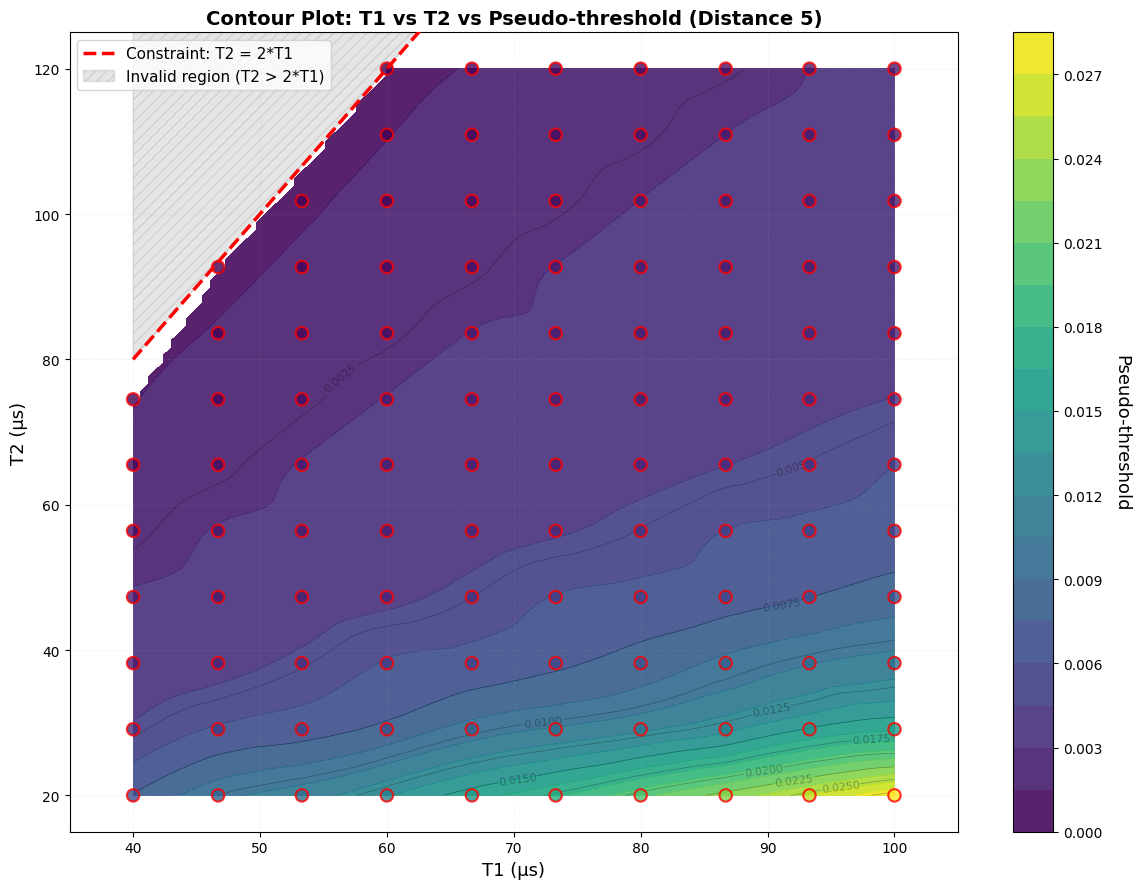


Contour plot shows the pseudo-threshold landscape with constraint boundary.


In [11]:
# Alternative view: Contour plot with constraint boundary
fig, ax = plt.subplots(1, 1, figsize=(12, 9))

# Create contour plot
contour = ax.contourf(T1_mesh, T2_mesh, Threshold_mesh, 
                      levels=20, cmap='viridis', alpha=0.9)

# Add contour lines
contour_lines = ax.contour(T1_mesh, T2_mesh, Threshold_mesh, 
                           levels=10, colors='black', alpha=0.3, linewidths=0.5)
ax.clabel(contour_lines, inline=True, fontsize=8, fmt='%.4f')

# Plot original data points
scatter = ax.scatter(t1_data, t2_data, c=threshold_data, 
                    cmap='viridis', s=80, edgecolor='red', 
                    linewidth=1.5, alpha=0.8, marker='o', zorder=5)

# Add constraint boundary line: T2 = 2*T1
t1_boundary = np.linspace(t1_data.min(), t1_data.max(), 100)
t2_boundary = 2 * t1_boundary
ax.plot(t1_boundary, t2_boundary, 'r--', linewidth=2.5, 
        label='Constraint: T2 = 2*T1', zorder=10)

# Fill the invalid region (T2 > 2*T1)
ax.fill_between(t1_boundary, t2_boundary, t2_data.max() + 10, 
                alpha=0.2, color='gray', label='Invalid region (T2 > 2*T1)', 
                zorder=1, hatch='///')

# Colorbar
cbar = plt.colorbar(contour, ax=ax)
cbar.set_label('Pseudo-threshold', fontsize=13, rotation=270, labelpad=20)

# Labels and title
ax.set_xlabel('T1 (µs)', fontsize=13)
ax.set_ylabel('T2 (µs)', fontsize=13)
ax.set_title('Contour Plot: T1 vs T2 vs Pseudo-threshold (Distance 5)', 
             fontsize=14, fontweight='bold')

# Set axis limits
ax.set_xlim(t1_data.min() - 5, t1_data.max() + 5)
ax.set_ylim(t2_data.min() - 5, min(t2_data.max() + 5, 2*t1_data.max() + 10))

# Grid and legend
ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
ax.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()

print("\nContour plot shows the pseudo-threshold landscape with constraint boundary.")